# Input data generation

## Accepts .h5 and .imzml formats

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import cv2
from hyres_utils import hyres_generator
from hyres_evals import entropy_rank, info_montage

C:\Users\yx2011\AppData\Local\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


### Input directory

In [2]:
# this is the directory that contains your .imzml, .h5 .tif etc.
input_dir = ''

### Generate HR input/training images from HSI datasets in input directory

In [3]:
for file in glob.glob(input_dir+"/*.h5"):
    _,_ =hyres_generator(os.path.basename(file), input_dir)
print('training images generated from %d' % len(glob.glob(input_dir+"/*.h5"))+' datasets.')

2026_06_09_02_TQ_D_25um_4Hz_MG05BS_06_ROI_17_18_19_analyte_only.h5
2026_06_09_03_TQ_D_25um_4Hz_MG05BS_06_ROI_16.h5
2026_06_10_02_TQ_D_25um_4Hz_MG03SC_05_ROI_10_11.h5
2026_06_11_02_TQ_D_25um_4Hz_MG03BS_06_ROI_06.h5
2026_06_11_03_TQ_D_25um_4Hz_MG03BS_06_ROI_07.h5
2026_06_11_04_TQ_D_25um_4Hz_MG03BS_06_ROI_08_09.h5
2026_06_12_02_TQ_D_25um_4Hz_MG01BS_09_ROI_08_09.h5
2026_06_15_02_TQ_D_25um_4Hz_MKO35_10_ROI_19.h5
2026_06_15_03_TQ_D_25um_4Hz_MKO35_10_ROI_20.h5
2026_06_15_05_TQ_D_25um_4Hz_MKO44_10_ROI_1.h5
2026_06_15_06_TQ_D_25um_4Hz_MKO44_10_ROI_2.h5
2026_06_16_02_TQ_D_25um_4Hz_MKO43_04_ROI_1_2_3.h5
2026_06_17_01_TQ_D_25um_4Hz_MKO33_04_ROI_1.h5
2026_06_17_02_TQ_D_25um_4Hz_MKO21_09_ROI_1_2_3.h5
2026_06_18_01_TQ_D_25um_4Hz_MKO15_09_ROI_1_2.h5
2026_06_19_01_TQ_D_25um_4Hz_MKO46_05_ROI_1_2.h5
training images generated from 16 datasets.


### Visualise the top 10 features in the HSI dataset that contain the most information (by Shannon's entropy)

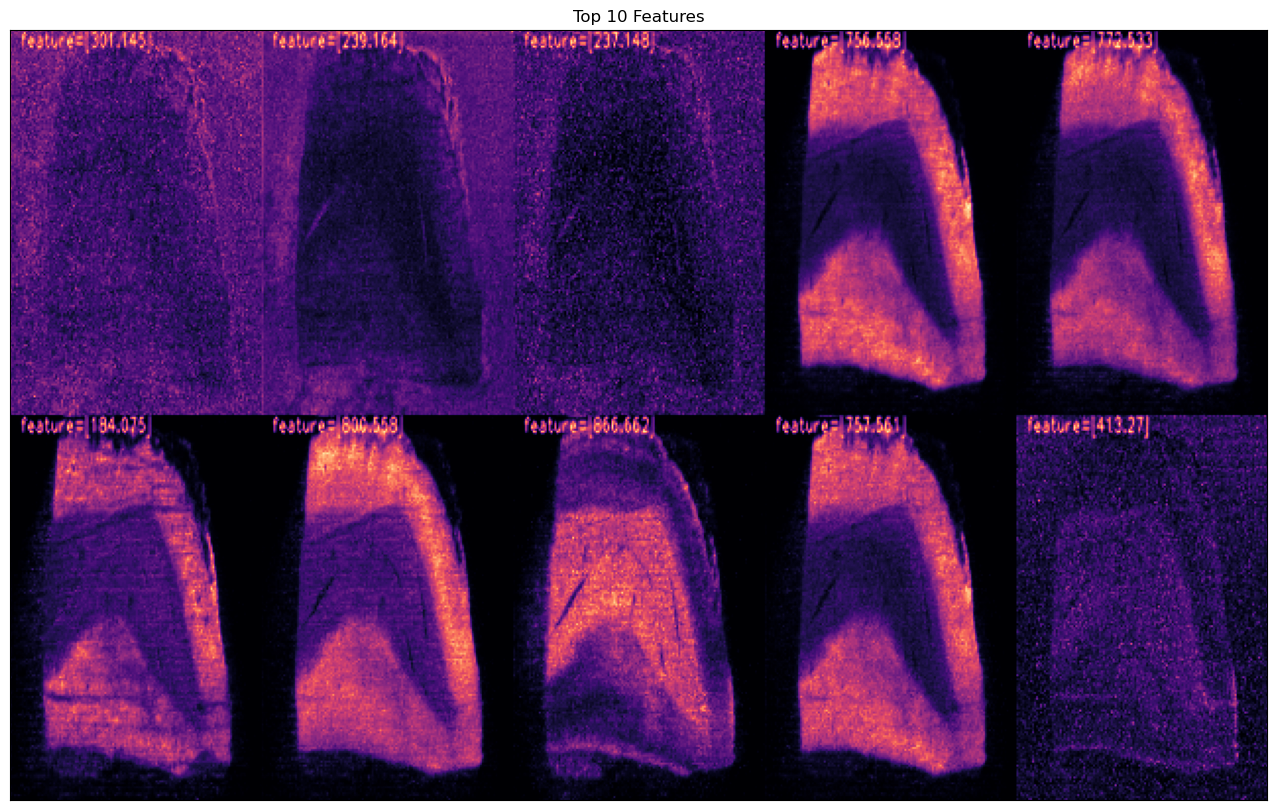

In [5]:
example_dir = file[:-3]
ents, rank = entropy_rank(example_dir)

montages = info_montage(example_dir, rank)
for montage in montages:
    fig, ax = plt.subplots()
    ax.set_title('Top 10 Features')
    ax.set_xticks([]) 
    ax.set_yticks([])  
    ax.imshow(cv2.cvtColor(montage, cv2.COLOR_BGR2GRAY), cmap = 'magma');
    fig = plt.gcf()
    fig.set_size_inches(20, 10)

### Generate synthetic LR images to pair with HR images for training